In [920]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [921]:

df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [922]:

print("Dataset Shape:", df.shape)


Dataset Shape: (1460, 81)


In [923]:

print(df.head())
print(df.columns.tolist())


   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD   

In [924]:
df = pd.read_csv("train.csv")
print(df.shape)

(1460, 81)


In [925]:

df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [926]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [927]:

missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [928]:

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

missing_table = missing_table[missing_table["Missing Values"] > 0]

print(missing_table.sort_values(
    by="Missing Percentage",
    ascending=False
))


              Missing Values  Missing Percentage
PoolQC                  1453           99.520548
MiscFeature             1406           96.301370
Alley                   1369           93.767123
Fence                   1179           80.753425
MasVnrType               872           59.726027
FireplaceQu              690           47.260274
LotFrontage              259           17.739726
GarageType                81            5.547945
GarageYrBlt               81            5.547945
GarageFinish              81            5.547945
GarageQual                81            5.547945
GarageCond                81            5.547945
BsmtExposure              38            2.602740
BsmtFinType2              38            2.602740
BsmtQual                  37            2.534247
BsmtCond                  37            2.534247
BsmtFinType1              37            2.534247
MasVnrArea                 8            0.547945
Electrical                 1            0.068493


In [929]:

numerical_columns = df.select_dtypes(include=np.number).columns

categorical_columns = df.select_dtypes(include='object').columns

print("Numerical Columns:")
print(numerical_columns.tolist())

print("\nCategorical Columns:")
print(categorical_columns.tolist())

print("\nTotal Numerical Columns:", len(numerical_columns))
print("Total Categorical Columns:", len(categorical_columns))


Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'Fireplac

In [930]:

df.describe()


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [931]:

print("House Price Statistics")

print(df["SalePrice"].describe())

print("\nAverage House Price:", df["SalePrice"].mean())

print("Minimum House Price:", df["SalePrice"].min())

print("Maximum House Price:", df["SalePrice"].max())

print("Median House Price:", df["SalePrice"].median())


House Price Statistics
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Average House Price: 180921.19589041095
Minimum House Price: 34900
Maximum House Price: 755000
Median House Price: 163000.0


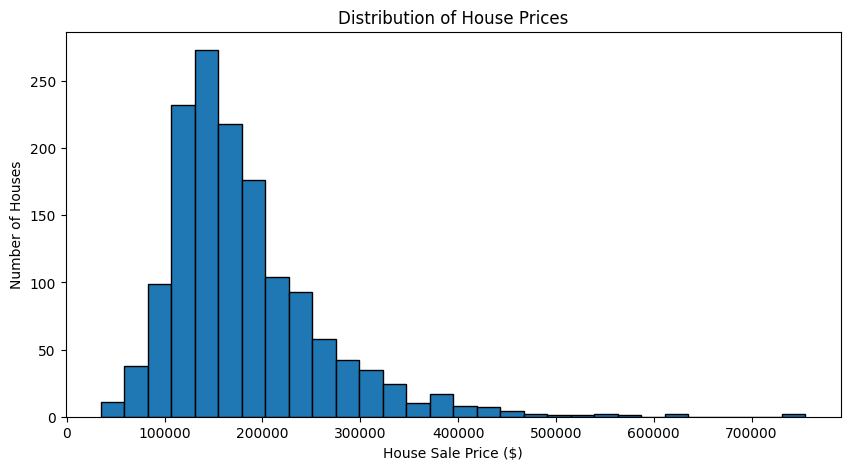

In [932]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["SalePrice"], bins=30, edgecolor="black")

plt.title("Distribution of House Prices")
plt.xlabel("House Sale Price ($)")
plt.ylabel("Number of Houses")

plt.show()


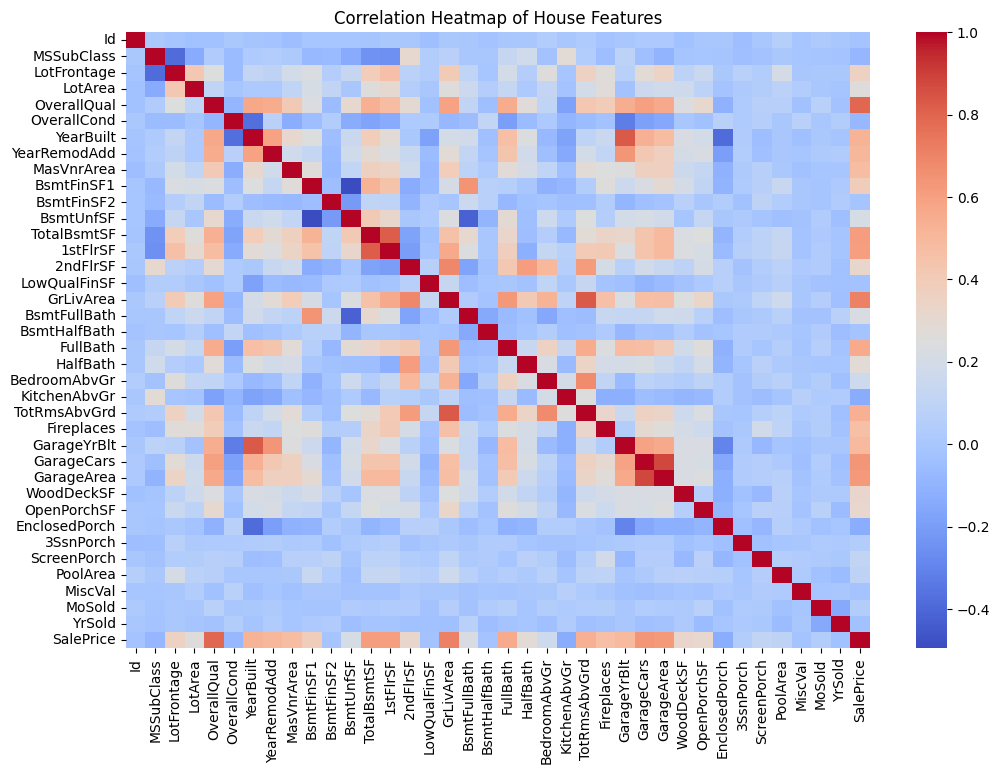

In [933]:

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Heatmap of House Features")
plt.show()


In [934]:

# Define ordinal variables and their order

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

# Convert ordinal columns into ordered categorical variables

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(
        df[col],
        categories=order,
        ordered=True
    )

# Identify numerical and categorical columns

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(include="object").columns.tolist()

ordinal_cols = list(ordinal_map.keys()) + ["OverallQual"]

# Create summary table

summary = []

for col in df.columns:

    if col in ordinal_cols:
        variable_type = "Ordinal"

    elif col in numerical_cols:
        variable_type = "Numerical"

    else:
        variable_type = "Categorical"

    summary.append({
        "Column Name": col,
        "Type": variable_type,
        "Unique Values": df[col].nunique(),
        "Example Values": list(df[col].dropna().unique()[:5])
    })

summary_df = pd.DataFrame(summary)

print("Variable Classification Summary")
display(summary_df)

# Display total variables in each category

print("\nTotal Numerical Columns:", len(numerical_cols))
print("Total Categorical Columns:", len(categorical_cols))
print("Total Ordinal Columns:", len(ordinal_cols))


Variable Classification Summary


,Column Name,Type,Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9, 12, 10]"
77,YrSold,Numerical,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,Categorical,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"



Total Numerical Columns: 38
Total Categorical Columns: 41
Total Ordinal Columns: 3


In [935]:

import pandas as pd
import numpy as np

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
submission = pd.read_csv("sample_submission.csv")

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)
print("Sample Submission Shape:", submission.shape)

print("\nTraining Dataset:")
display(train.head())

print("\nTesting Dataset:")
display(test.head())

print("\nSample Submission:")
display(submission.head())


Training Dataset Shape: (1460, 81)
Testing Dataset Shape: (1459, 80)
Sample Submission Shape: (1459, 2)

Training Dataset:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Testing Dataset:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1461,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,...,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal
1,1462,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal
2,1463,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal
3,1464,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,6,2010,WD,Normal
4,1465,120,RL,43.0,5005,Pave,NaN,IR1,HLS,AllPub,...,144,0,NaN,NaN,NaN,0,1,2010,WD,Normal



Sample Submission:


,Id,SalePrice
0,1461,169277.052498
1,1462,187758.393989
2,1463,183583.683570
3,1464,179317.477511
4,1465,150730.079977


In [936]:

print("Missing Values in Training Data:")
print(train.isnull().sum().sort_values(ascending=False).head(20))

print("\nMissing Values in Testing Data:")
print(test.isnull().sum().sort_values(ascending=False).head(20))


Missing Values in Training Data:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Condition2         0
dtype: int64

Missing Values in Testing Data:
PoolQC          1456
MiscFeature     1408
Alley           1352
Fence           1169
MasVnrType       894
FireplaceQu      730
LotFrontage      227
GarageYrBlt       78
GarageCond        78
GarageFinish      78
GarageQual        78
GarageType        76
BsmtCond          45
BsmtQual          44
BsmtExposure      44
BsmtFinType1      42
BsmtFinType2      42
MasVnrArea        15
MSZoning           4
BsmtHalfBath       2
dtype: int64


In [937]:

# Separate numerical and categorical columns

numeric_cols = train.select_dtypes(include=np.number).columns.tolist()

categorical_cols = train.select_dtypes(include="object").columns.tolist()

# Fill missing numerical values using median

for col in numeric_cols:
    if train[col].isnull().sum() > 0:
        median_value = train[col].median()
        train[col] = train[col].fillna(median_value)

# Fill missing categorical values using mode

for col in categorical_cols:
    if train[col].isnull().sum() > 0:
        mode_value = train[col].mode()[0]
        train[col] = train[col].fillna(mode_value)

print("Missing values handled in training data.")

print("\nRemaining missing values:")
print(train.isnull().sum().sum())


Missing values handled in training data.

Remaining missing values:
0


In [938]:
# Step 3: Descriptive Statistics

for col in ["SalePrice", "GrLivArea", "LotArea"]:
    print("\nStatistics for", col)

    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Variance:", df[col].var())
    print("Range:", df[col].max() - df[col].min())
    print("IQR:", df[col].quantile(0.75) - df[col].quantile(0.25))
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


Statistics for SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

Statistics for GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

Statistics for LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


In [939]:
# Categorical Statistics

for col in ["Neighborhood", "HouseStyle"]:
    print("\nValue counts for", col)
    print(df[col].value_counts())

    print("Most common value:", df[col].mode()[0])


Value counts for Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64
Most common value: NAmes

Value counts for HouseStyle
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64
Most common value: 1Story


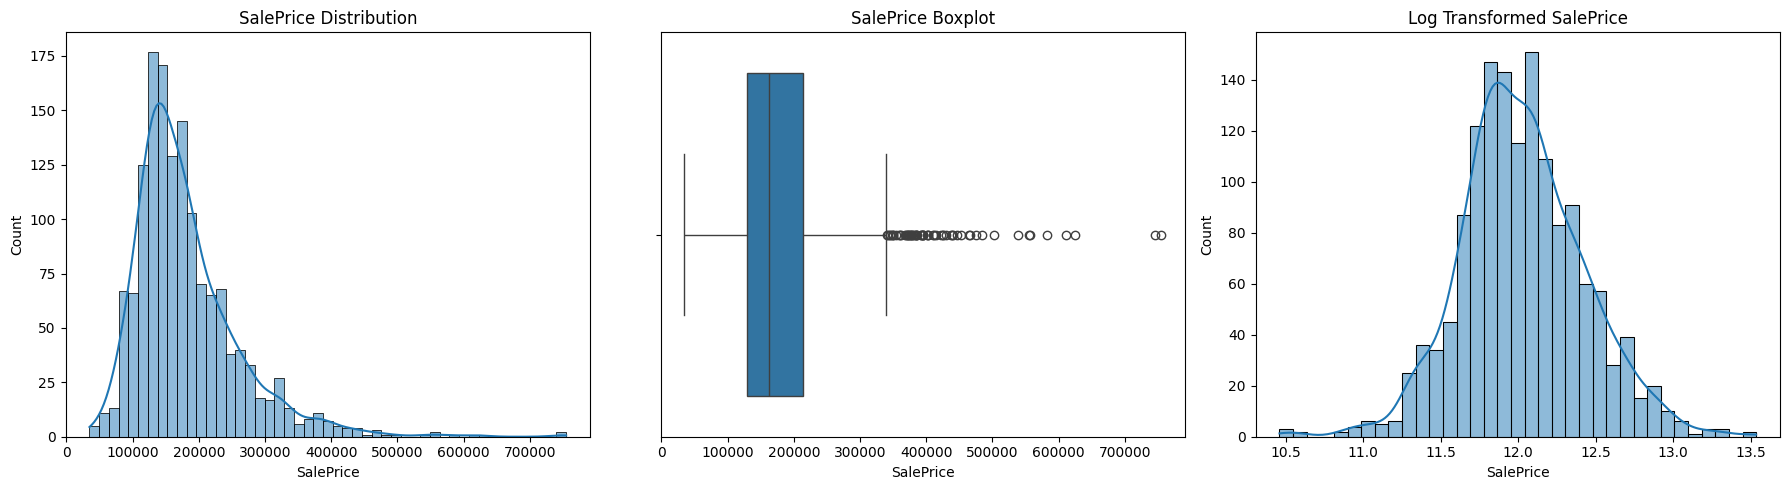

In [940]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. SalePrice Histogram with KDE
sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")

# 2. SalePrice Boxplot
sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")

# 3. Log-transformed SalePrice
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[2])
axes[2].set_title("Log Transformed SalePrice")

plt.tight_layout()
plt.show()

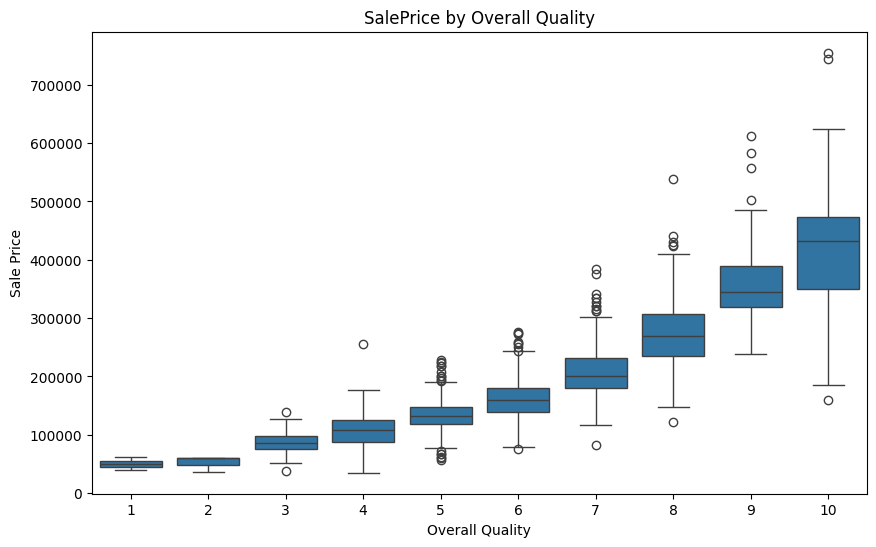

In [941]:
plt.figure(figsize=(10, 6))

sns.boxplot(x="OverallQual", y="SalePrice", data=df)

plt.title("SalePrice by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

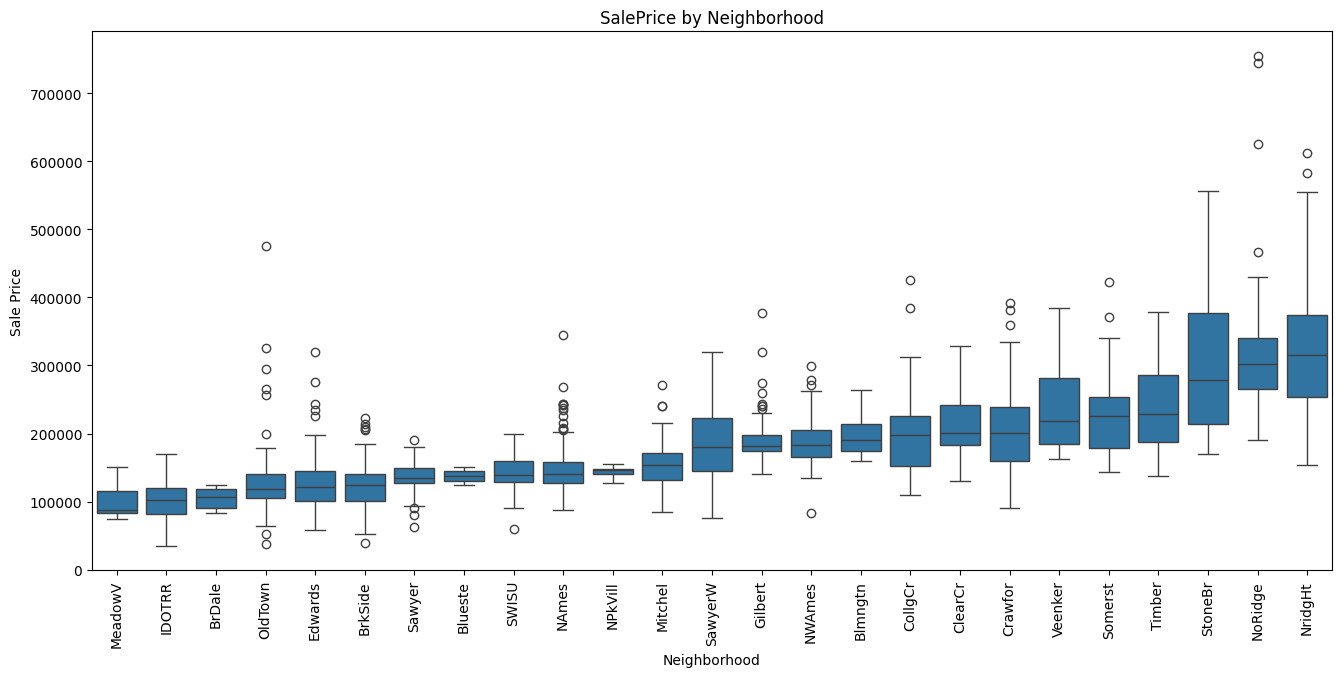

In [942]:
plt.figure(figsize=(16, 7))

order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

sns.boxplot(x="Neighborhood", y="SalePrice", data=df, order=order)

plt.title("SalePrice by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")
plt.xticks(rotation=90)

plt.show()

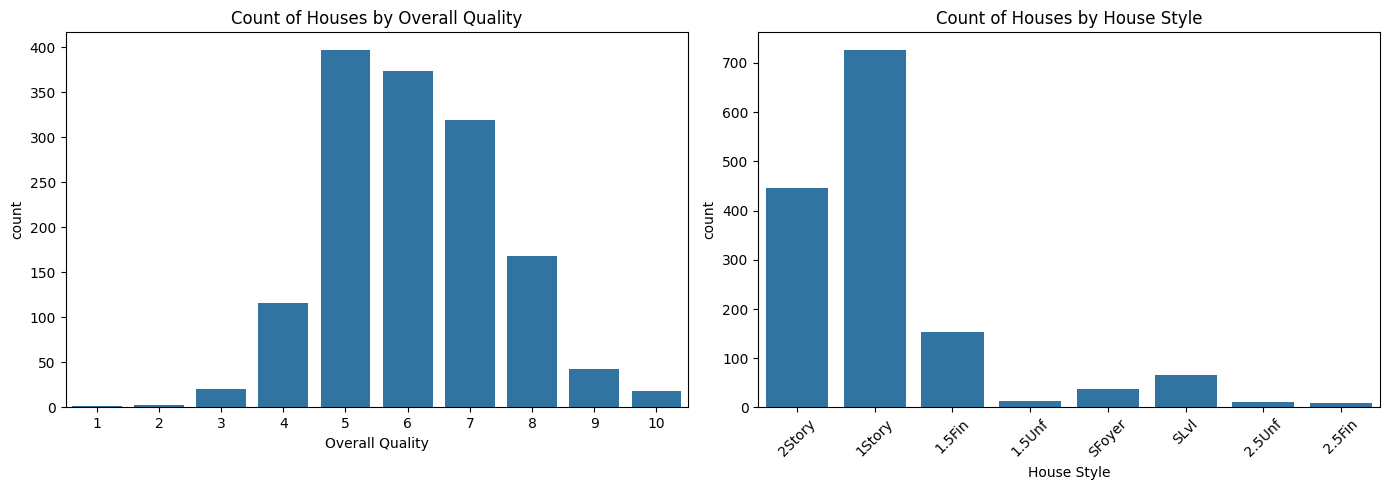

In [943]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x="OverallQual", data=df, ax=axes[0])
axes[0].set_title("Count of Houses by Overall Quality")
axes[0].set_xlabel("Overall Quality")

sns.countplot(x="HouseStyle", data=df, ax=axes[1])
axes[1].set_title("Count of Houses by House Style")
axes[1].set_xlabel("House Style")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [944]:
# Correlation Matrix
numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr(method="pearson")

print(correlation_matrix)

                     Id  MSSubClass  LotFrontage   LotArea  OverallQual  \
Id             1.000000    0.011156    -0.010601 -0.033226    -0.028365   
MSSubClass     0.011156    1.000000    -0.386347 -0.139781     0.032628   
LotFrontage   -0.010601   -0.386347     1.000000  0.426095     0.251646   
LotArea       -0.033226   -0.139781     0.426095  1.000000     0.105806   
OverallQual   -0.028365    0.032628     0.251646  0.105806     1.000000   
OverallCond    0.012609   -0.059316    -0.059213 -0.005636    -0.091932   
YearBuilt     -0.012713    0.027850     0.123349  0.014228     0.572323   
YearRemodAdd  -0.021998    0.040581     0.088866  0.013788     0.550684   
MasVnrArea    -0.050298    0.022936     0.193458  0.104160     0.411876   
BsmtFinSF1    -0.005024   -0.069836     0.233633  0.214103     0.239666   
BsmtFinSF2    -0.005968   -0.065649     0.049900  0.111170    -0.059119   
BsmtUnfSF     -0.007940   -0.140759     0.132644 -0.002618     0.308159   
TotalBsmtSF   -0.015415  

In [945]:
# Top 10 features correlated with SalePrice

saleprice_corr = correlation_matrix["SalePrice"].drop("SalePrice")

top_10 = saleprice_corr.abs().sort_values(ascending=False).head(10)

print("Top 10 Features Correlated with SalePrice:")
print(saleprice_corr.loc[top_10.index])

Top 10 Features Correlated with SalePrice:
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


In [946]:
# Top 3 features
top_3 = top_10.head(3).index

for col in top_3:
    print("\nFeature:", col)
    print("Correlation with SalePrice:", correlation_matrix.loc[col, "SalePrice"])
    print("Covariance with SalePrice:", numeric_df[col].cov(df["SalePrice"]))


Feature: OverallQual
Correlation with SalePrice: 0.7909816005838053
Covariance with SalePrice: 86904.12583679947

Feature: GrLivArea
Correlation with SalePrice: 0.7086244776126515
Covariance with SalePrice: 29581866.743236605

Feature: GarageCars
Correlation with SalePrice: 0.6404091972583519
Covariance with SalePrice: 38020.18135897171


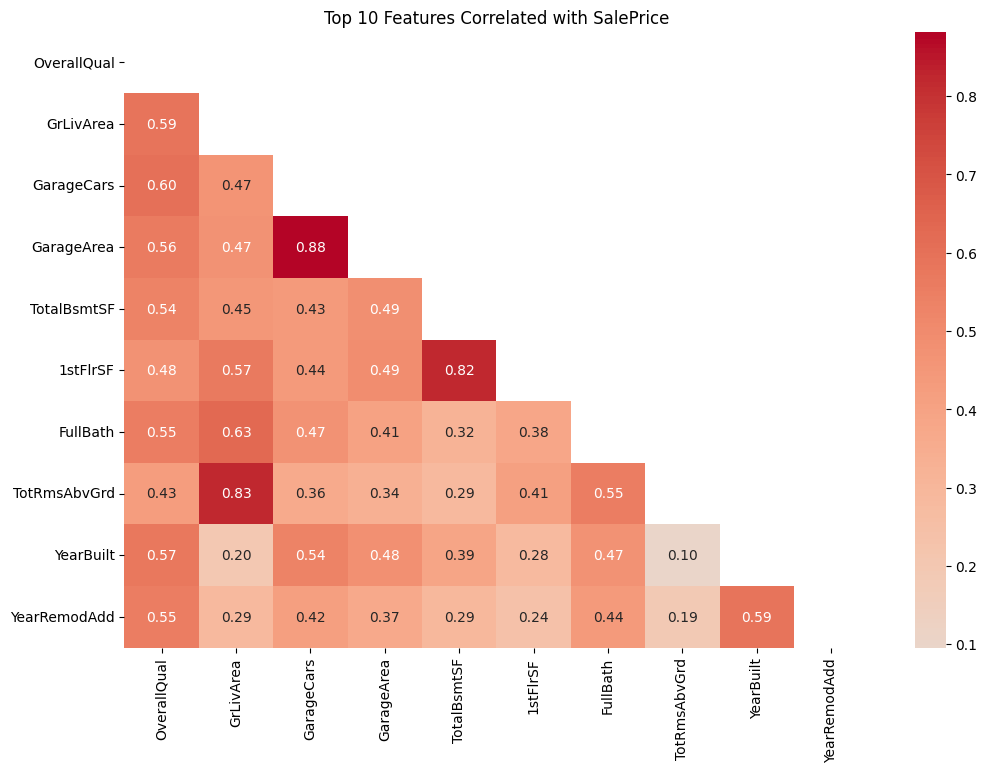

In [947]:
plt.figure(figsize=(12, 8))

top_10_corr = numeric_df[top_10.index].corr()

mask = np.triu(np.ones_like(top_10_corr, dtype=bool))

sns.heatmap(
    top_10_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    mask=mask
)

plt.title("Top 10 Features Correlated with SalePrice")
plt.show()

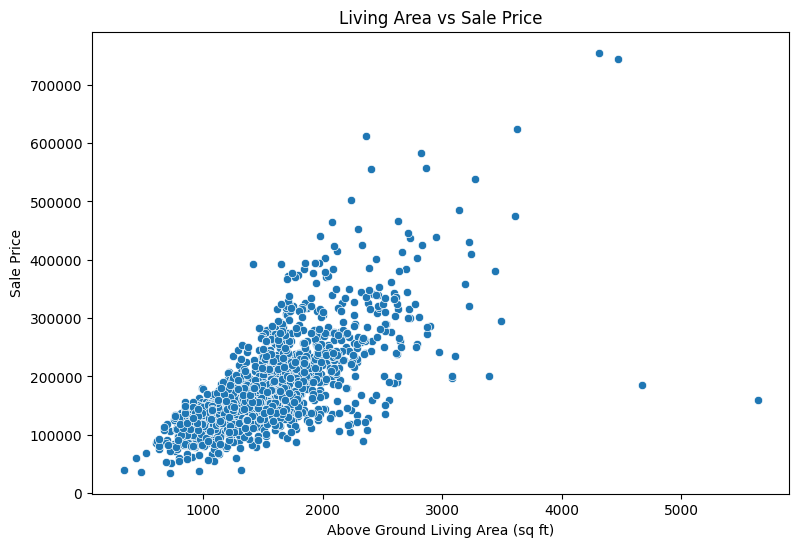

In [948]:
plt.figure(figsize=(9, 6))

sns.scatterplot(data=df, x="GrLivArea", y="SalePrice")

plt.title("Living Area vs Sale Price")
plt.xlabel("Above Ground Living Area (sq ft)")
plt.ylabel("Sale Price")

plt.show()

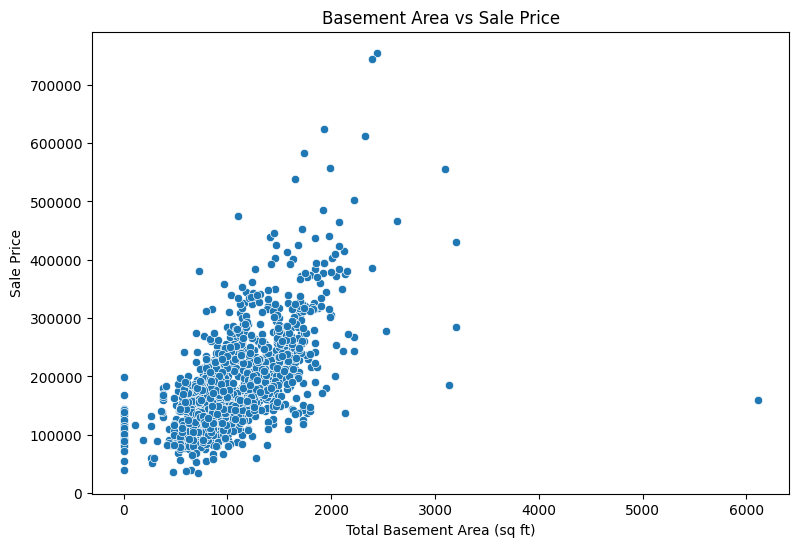

In [949]:
plt.figure(figsize=(9, 6))

sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice")

plt.title("Basement Area vs Sale Price")
plt.xlabel("Total Basement Area (sq ft)")
plt.ylabel("Sale Price")

plt.show()

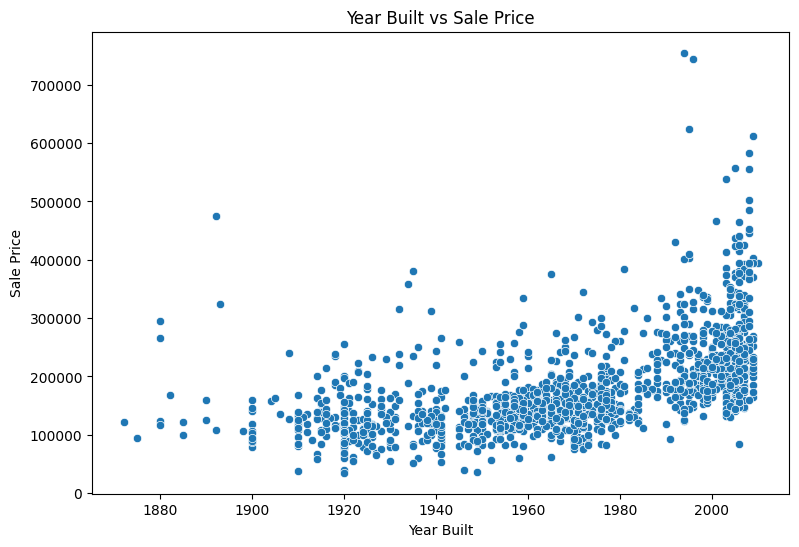

In [950]:
plt.figure(figsize=(9, 6))

sns.scatterplot(data=df, x="YearBuilt", y="SalePrice")

plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")

plt.show()

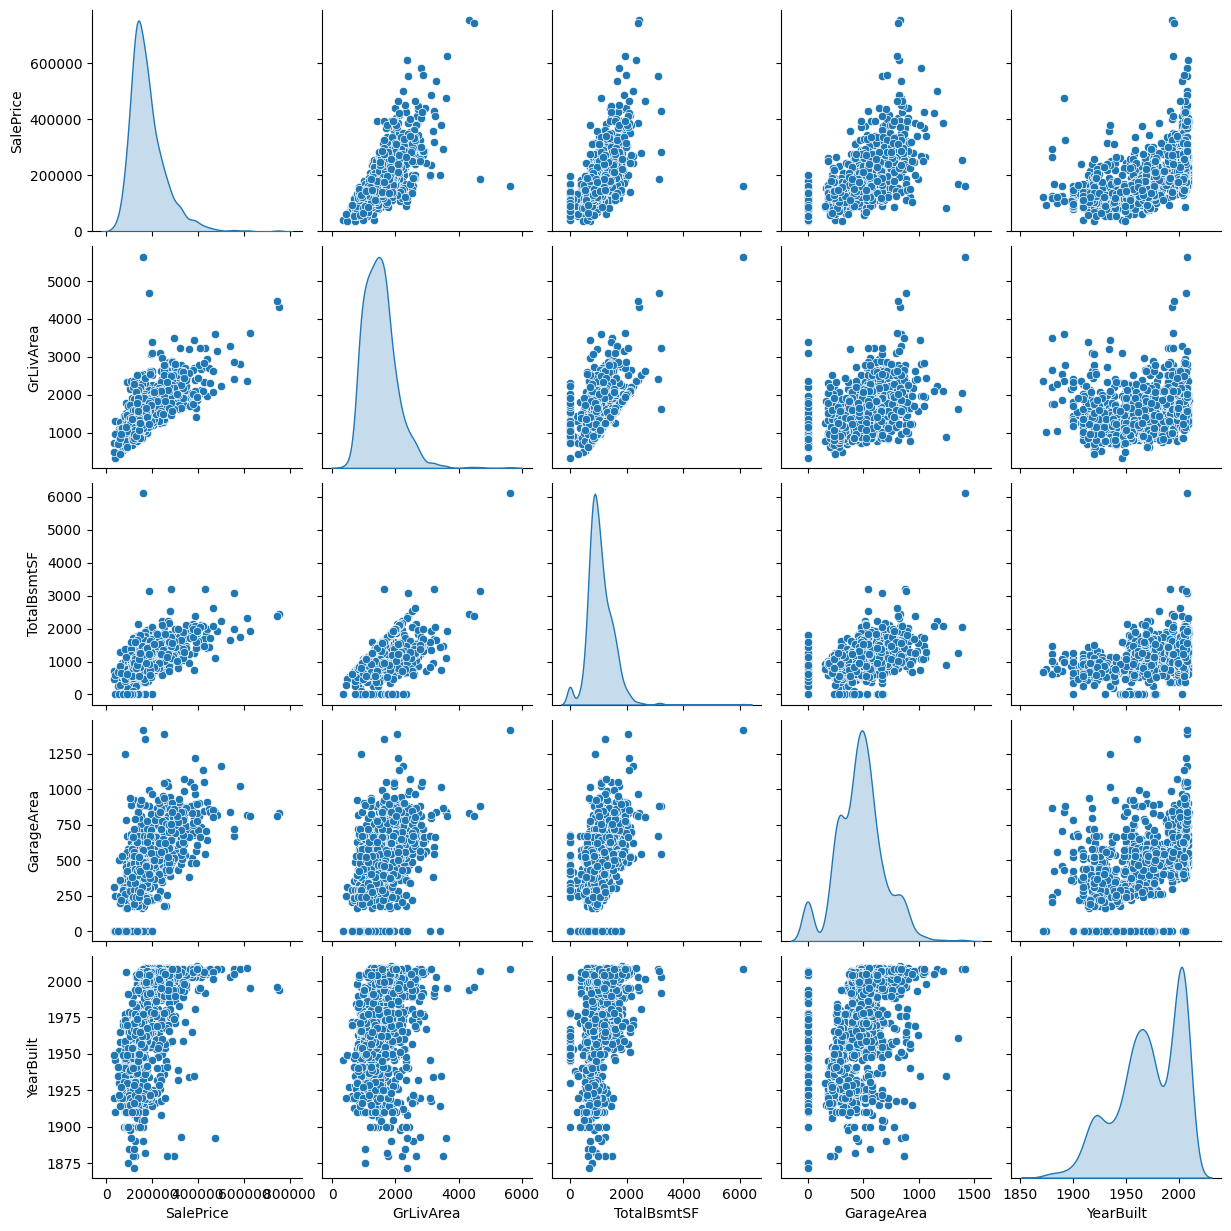

In [951]:
selected_columns = [
    "SalePrice",
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea",
    "YearBuilt"
]

sns.pairplot(
    df[selected_columns],
    diag_kind="kde"
)

plt.show()

In [952]:
def find_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    return outliers

for col in ["GrLivArea", "SalePrice"]:
    outliers = find_outliers_iqr(df, col)

    print("\nOutliers in", col, ":", len(outliers))


Outliers in GrLivArea : 31

Outliers in SalePrice : 61


In [953]:
from scipy.stats import zscore

for col in ["GrLivArea", "SalePrice"]:
    z_scores = zscore(df[col])

    outliers = df[abs(z_scores) > 3]

    print("Z-score outliers in", col, ":", len(outliers))

Z-score outliers in GrLivArea : 16
Z-score outliers in SalePrice : 22


In [954]:
for col in ["GrLivArea", "SalePrice"]:

    iqr_outliers = find_outliers_iqr(df, col).index

    z_scores = zscore(df[col])
    z_outliers = df.index[abs(z_scores) > 3]

    common_outliers = set(iqr_outliers).intersection(set(z_outliers))

    print("\nColumn:", col)
    print("IQR Outliers:", len(iqr_outliers))
    print("Z-score Outliers:", len(z_outliers))
    print("Common Outliers:", len(common_outliers))


Column: GrLivArea
IQR Outliers: 31
Z-score Outliers: 16
Common Outliers: 16

Column: SalePrice
IQR Outliers: 61
Z-score Outliers: 22
Common Outliers: 22


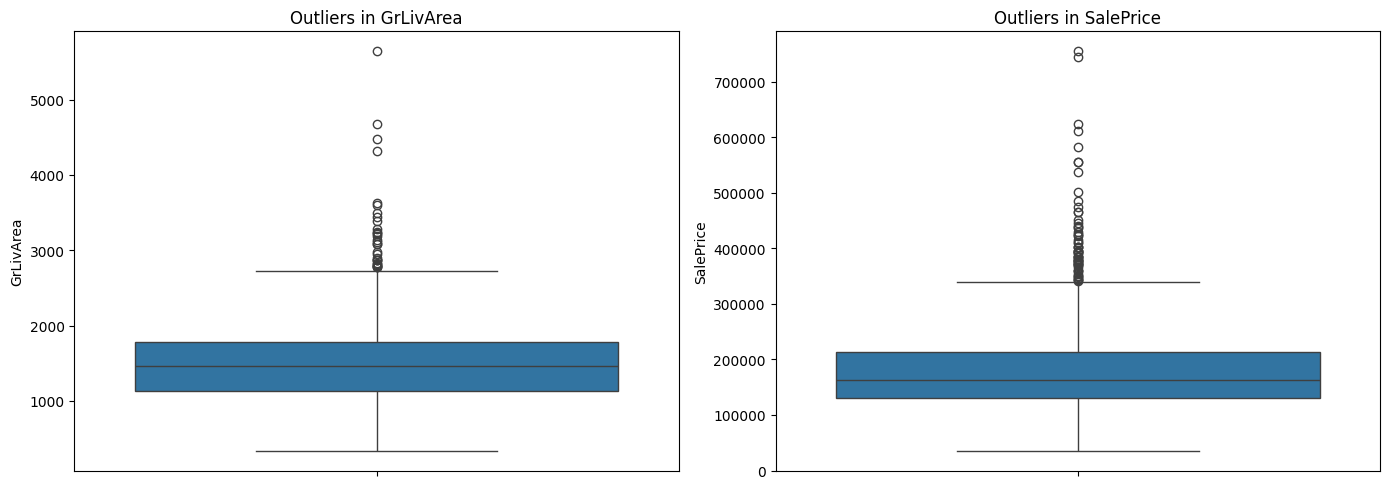

In [955]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["GrLivArea"], ax=axes[0])
axes[0].set_title("Outliers in GrLivArea")

sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("Outliers in SalePrice")

plt.tight_layout()
plt.show()

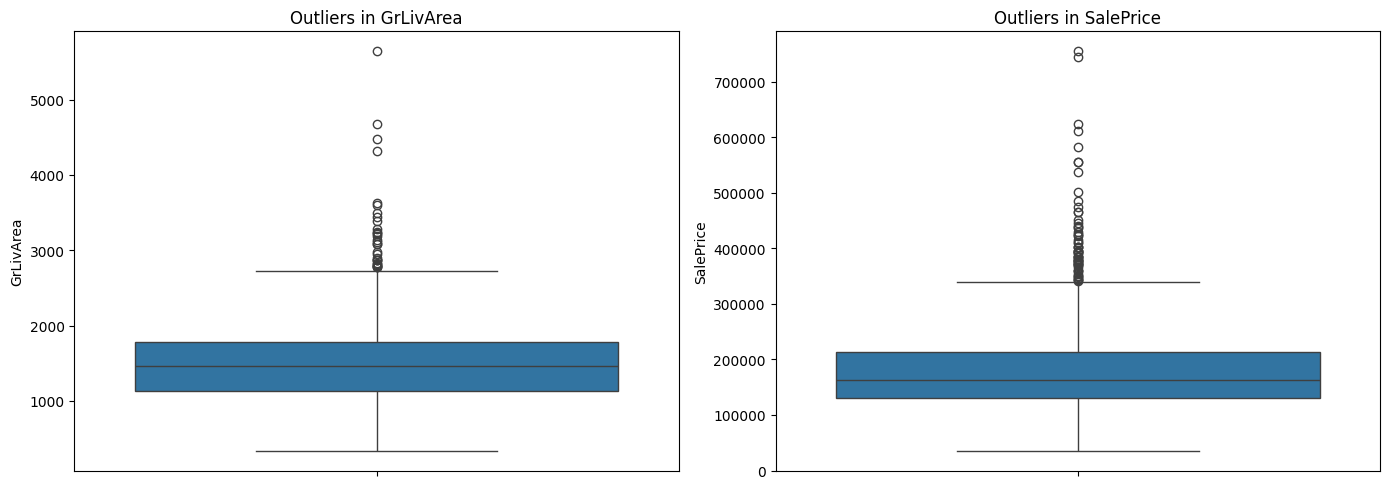

In [956]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df["GrLivArea"], ax=axes[0])
axes[0].set_title("Outliers in GrLivArea")

sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("Outliers in SalePrice")

plt.tight_layout()
plt.show()

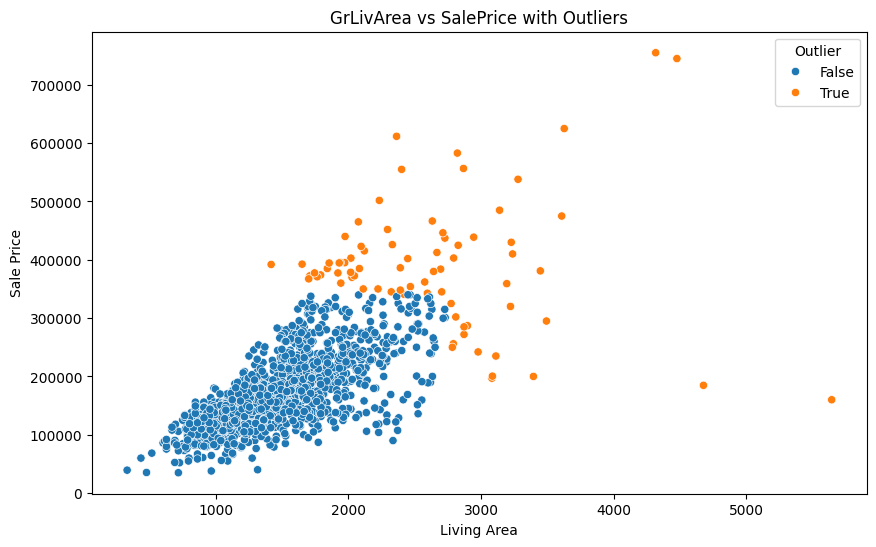

In [957]:
iqr_outliers = find_outliers_iqr(df, "GrLivArea").index
iqr_saleprice = find_outliers_iqr(df, "SalePrice").index

outlier_indices = set(iqr_outliers).union(set(iqr_saleprice))

df["Outlier"] = df.index.isin(outlier_indices)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="Outlier"
)

plt.title("GrLivArea vs SalePrice with Outliers")
plt.xlabel("Living Area")
plt.ylabel("Sale Price")

plt.show()

In [958]:
# Check duplicate rows

duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

if duplicates > 0:
    df.drop_duplicates(inplace=True)
    print("Duplicates removed.")

print("New dataset shape:", df.shape)

Number of duplicate rows: 0
New dataset shape: (1460, 82)


In [959]:
# Check categorical columns

categorical_cols = df.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    print("\nColumn:", col)
    print(df[col].value_counts().head(10))


Column: MSZoning
MSZoning
RL         1151
RM          218
FV           65
RH           16
C (all)      10
Name: count, dtype: int64

Column: Street
Street
Pave    1454
Grvl       6
Name: count, dtype: int64

Column: Alley
Alley
Grvl    50
Pave    41
Name: count, dtype: int64

Column: LotShape
LotShape
Reg    925
IR1    484
IR2     41
IR3     10
Name: count, dtype: int64

Column: LandContour
LandContour
Lvl    1311
Bnk      63
HLS      50
Low      36
Name: count, dtype: int64

Column: Utilities
Utilities
AllPub    1459
NoSeWa       1
Name: count, dtype: int64

Column: LotConfig
LotConfig
Inside     1052
Corner      263
CulDSac      94
FR2          47
FR3           4
Name: count, dtype: int64

Column: LandSlope
LandSlope
Gtl    1382
Mod      65
Sev      13
Name: count, dtype: int64

Column: Neighborhood
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
Name: count, dtype: int

In [960]:
# Check missing values

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("Columns with missing values:")
print(missing_values.sort_values(ascending=False))

print("\nTotal missing values:", df.isnull().sum().sum())

Columns with missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

Total missing values: 7829


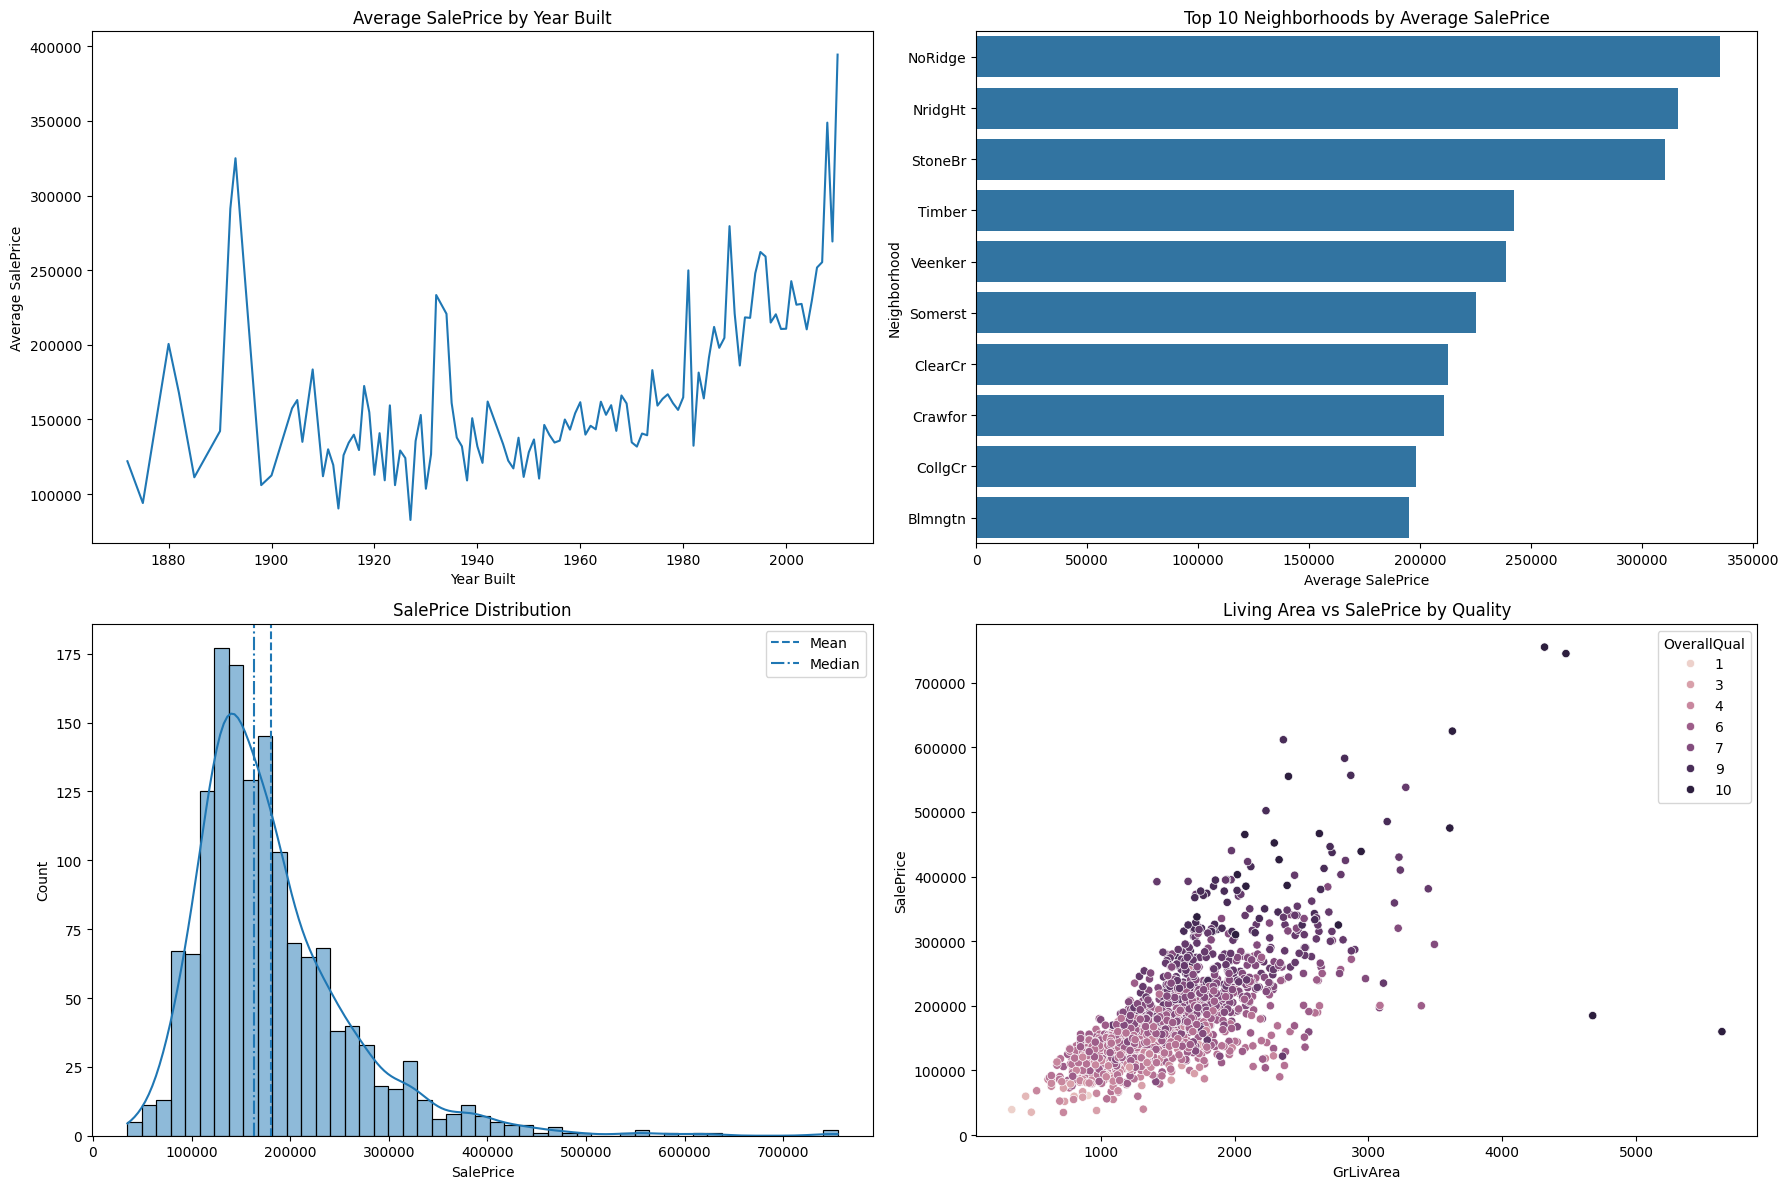

In [961]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Average SalePrice by Year Built
year_price = df.groupby("YearBuilt")["SalePrice"].mean()

axes[0, 0].plot(year_price.index, year_price.values)
axes[0, 0].set_title("Average SalePrice by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average SalePrice")

# 2. Top 10 Neighborhoods by Average SalePrice
neighborhood_price = df.groupby("Neighborhood")["SalePrice"].mean()
top_neighborhoods = neighborhood_price.sort_values(ascending=False).head(10)

sns.barplot(x=top_neighborhoods.values,
            y=top_neighborhoods.index,
            ax=axes[0, 1])

axes[0, 1].set_title("Top 10 Neighborhoods by Average SalePrice")
axes[0, 1].set_xlabel("Average SalePrice")

# 3. SalePrice Distribution with Mean and Median
sns.histplot(df["SalePrice"], kde=True, ax=axes[1, 0])

axes[1, 0].axvline(df["SalePrice"].mean(), linestyle="--",
                   label="Mean")

axes[1, 0].axvline(df["SalePrice"].median(), linestyle="-.",
                   label="Median")

axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].legend()

# 4. GrLivArea vs SalePrice by OverallQual
sns.scatterplot(data=df,
                x="GrLivArea",
                y="SalePrice",
                hue="OverallQual",
                ax=axes[1, 1])

axes[1, 1].set_title("Living Area vs SalePrice by Quality")

plt.tight_layout()

plt.savefig("eda_dashboard.png", dpi=300)

plt.show()

In [962]:
print("FINAL EDA PROJECT INSIGHTS")

print("1. SalePrice distribution is right-skewed.")

print("2. OverallQual has a strong positive relationship with SalePrice.")

print("3. Houses with larger living areas generally have higher prices.")

print("4. House prices vary across different neighborhoods.")

print("5. Some unusually large houses may be outliers.")

print("6. Many missing values indicate that certain house features are absent.")

FINAL EDA PROJECT INSIGHTS
1. SalePrice distribution is right-skewed.
2. OverallQual has a strong positive relationship with SalePrice.
3. Houses with larger living areas generally have higher prices.
4. House prices vary across different neighborhoods.
5. Some unusually large houses may be outliers.
6. Many missing values indicate that certain house features are absent.
